# Catalog-rank model comparison against human qrels

Compare selected path-aware `catalog-rank` runs against Lysandre’s human relevance grades. The benchmark contains 15 conditions. Runs evaluated on fewer conditions show their coverage.

The main metric is graded nDCG at several cutoffs. Higher-grade signals contribute more, and higher ranks contribute more. Model utility scores are used only to order candidates; they are not treated as human grades.

In [18]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display, Markdown
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

REPO = Path('/storage/lcostes/Similarity_benchmark')
sys.path.insert(0, str(REPO))
from src.datasets.local_relbench_dataset import LocalRelBenchDataset
from src.schema.schema_graph import SchemaGraph
from src.signals.candidates import candidate_from_dict
import importlib
import src.evaluation.ranking_metrics as ranking_metrics_module
importlib.reload(ranking_metrics_module)
ranking_metrics = ranking_metrics_module.ranking_metrics

ACTIVE_SUITES = ('all',)

SCORE_SCALE = '0-10'  # 'all', '0-10', or '0-100'
if SCORE_SCALE not in {'all', '0-10', '0-100'}:
    raise ValueError("SCORE_SCALE must be 'all', '0-10', or '0-100'")
RUN_DIR = lambda suite: REPO / 'results/rel-amazon/discovery/catalog-views'
RUN_FILES_BY_SCALE = {
    '0-100': {
        'GPT-6 Luna — none': 'catalog-rank-gpt-6-luna-path-aware.jsonl',
        'GPT-6 Luna — high': 'catalog-rank-gpt-6-luna-path-aware-high.jsonl',
        'GPT-5.6 Terra — high': 'catalog-rank-gpt-5.6-terra-high-path-aware.jsonl',
    },
    '0-10': {
        'GPT-6 Luna — none (0–10)': 'catalog-rank-gpt-6-luna-utility-0-10-path-aware.jsonl',
        'GPT-6 Luna — high (0–10)': 'catalog-rank-gpt-6-luna-utility-0-10-high-path-aware.jsonl',
        'GPT-5.6 Terra — high (0–10)': 'catalog-rank-gpt-5.6-terra-utility-0-10-high-path-aware.jsonl',
        'GPT-6 Sol — none (0–10)': 'catalog-rank-gpt-6-sol-utility-0-10-path-aware.jsonl',
        'GPT-6 Sol — high (0–10)': 'catalog-rank-gpt-6-sol-utility-0-10-high-path-aware.jsonl',
        'GPT-6 Astra — high (0–10)': 'catalog-rank-gpt-6-astra-utility-0-10-high-path-aware.jsonl',
    },
}
RUN_FILES = {}
for scale, scale_runs in RUN_FILES_BY_SCALE.items():
    if SCORE_SCALE not in {'all', scale}:
        continue
    for label, filename in scale_runs.items():
        if all((RUN_DIR(suite) / filename).is_file() for suite in ACTIVE_SUITES):
            RUN_FILES[label] = filename
QREL_FILE = lambda suite: REPO / 'annotations/rel-amazon/human/lysandre.jsonl'
METRICS = ('ndcg@1', 'ndcg@3', 'ndcg@5', 'ndcg@10')
GRAPH = SchemaGraph.from_manifest(LocalRelBenchDataset(REPO / 'data/dev/rel-amazon').schema)

def read_jsonl(path):
    with Path(path).open(encoding='utf-8') as stream:
        return [json.loads(line) for line in stream if line.strip()]

def ranking_value(signal):
    value = signal.get('utility_score', signal.get('score'))
    return value if isinstance(value, (int, float)) and not isinstance(value, bool) else None

def score_tie_spans(signals):
    """Map each signal ID to its inclusive rank span within equal scores."""
    spans, index = {}, 0
    while index < len(signals):
        score = ranking_value(signals[index])
        end = index
        if score is not None:
            while end + 1 < len(signals) and ranking_value(signals[end + 1]) == score:
                end += 1
        for item in signals[index:end + 1]:
            if isinstance(item.get('id'), str):
                spans[item['id']] = (index + 1, end + 1)
        index = end + 1
    return spans

def rank_span_label(span):
    return str(span[0]) if span[0] == span[1] else f'{span[0]}–{span[1]}'

def tied_top_ids(signals, k):
    return {candidate_id for candidate_id, (start, _) in score_tie_spans(signals).items() if start <= k}

print('Using the merged 15-condition benchmark')
for label, filename in RUN_FILES.items():
    print(f'{label}: ' + ', '.join(s for s in ACTIVE_SUITES if (RUN_DIR(s) / filename).is_file()))

Using the merged 15-condition benchmark
GPT-6 Luna — none (0–10): all
GPT-6 Luna — high (0–10): all
GPT-5.6 Terra — high (0–10): all
GPT-6 Sol — none (0–10): all
GPT-6 Sol — high (0–10): all
GPT-6 Astra — high (0–10): all


## Load human qrels and evaluate

Each run is scored against the matching human labels. Unjudged candidates are excluded from the ranked list rather than silently assigned grade 0.

In [19]:
def load_qrels(path):
    result = {}
    for row in read_jsonl(path):
        if (row.get('status') in {'complete', 'judged'}
            and isinstance(row.get('condition_id'), str)
            and isinstance(row.get('candidate_id'), str)
            and type(row.get('grade')) is int):
            result.setdefault(row['condition_id'], {})[row['candidate_id']] = row['grade']
    return result

qrels = {suite: load_qrels(QREL_FILE(suite)) for suite in ACTIVE_SUITES}
records, run_data = [], {}
for label, filename in RUN_FILES.items():
    for suite in ACTIVE_SUITES:
        path = RUN_DIR(suite) / filename
        if not path.is_file():
            raise FileNotFoundError(path)
        for run in read_jsonl(path):
            if run.get('method') != 'catalog-rank' or run.get('signal_catalog') != 'path-aware':
                raise ValueError(f'Unexpected method/catalog in {path}')
            cid = run['condition_id']
            grades = qrels[suite].get(cid, {})
            judged_signals = [s for s in run.get('signals', []) if s.get('id') in grades]
            ranked = [s['id'] for s in judged_signals]
            ranked_scores = [ranking_value(s) for s in judged_signals]
            records.append({'run': label, 'suite': suite, 'condition_id': cid,
                            'condition': run.get('condition', ''), 'judged': len(grades),
                            'ranked_judged': len(ranked),
                            **ranking_metrics(ranked, grades, ranked_scores=ranked_scores)})
            run_data[(label, suite, cid)] = run
per_condition = pd.DataFrame(records).sort_values(['suite', 'condition_id', 'run'])
display(Markdown('### Coverage'))
display(per_condition.groupby('run', as_index=False).agg(
    conditions=('condition_id', 'nunique'), min_qrels=('judged', 'min'),
    min_ranked_judged=('ranked_judged', 'min')))
print(f'{per_condition.condition_id.nunique()} benchmark conditions have at least one run.')


### Coverage

,run,conditions,min_qrels,min_ranked_judged
0,GPT-5.6 Terra — high (0–10),15,39,39
1,GPT-6 Astra — high (0–10),4,39,39
2,GPT-6 Luna — high (0–10),15,39,39
3,GPT-6 Luna — none (0–10),15,39,39
4,GPT-6 Sol — high (0–10),15,39,39
5,GPT-6 Sol — none (0–10),15,39,39


15 benchmark conditions have at least one run.


## Token usage

Compare average tokens per scored signal across each run’s available conditions. Counts are weighted by the number of signals; reasoning-token averages are blank unless every result reports them.


### Average token use per signal

,Signals scored,Avg input tokens / signal,Avg output tokens / signal,Avg reasoning tokens / signal,Avg total tokens / signal,Avg responses / signal
run,,,,,,
GPT-6 Luna — none (0–10),585,387.71,167.85,NaN,555.56,1.0
GPT-6 Luna — high (0–10),585,387.71,207.23,155.03,594.95,1.0
GPT-5.6 Terra — high (0–10),585,387.71,106.34,NaN,494.05,1.0
GPT-6 Sol — none (0–10),585,387.71,129.97,NaN,517.68,1.0
GPT-6 Sol — high (0–10),585,387.71,193.44,NaN,581.15,1.0
GPT-6 Astra — high (0–10),156,389.01,198.90,NaN,587.91,1.0


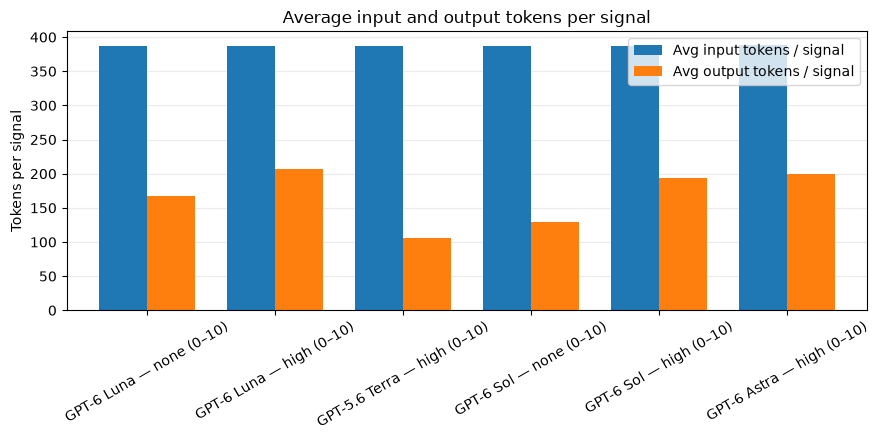

In [20]:
def token_usage_for_file(path):
    rows = read_jsonl(path)
    summaries = [row.get('token_usage') for row in rows]
    summaries = [item for item in summaries if isinstance(item, dict)]
    if not summaries:
        return None
    result = {'conditions': len(rows), 'conditions_with_usage': len(summaries)}
    for field in ('input_tokens', 'output_tokens', 'total_tokens'):
        values = [item.get(field) for item in summaries]
        result[field] = sum(values) if len(summaries) == len(rows) and all(type(v) is int for v in values) else None
    result['signals_scored'] = sum(int(item.get('signals_scored', 0)) for item in summaries)
    result['responses'] = sum(int(item.get('responses', 0)) for item in summaries)
    result['reasoning_token_responses_reported'] = sum(
        int(item.get('reasoning_token_responses_reported', 0)) for item in summaries
    )
    reasoning_values = [item.get('reasoning_tokens') for item in summaries]
    result['reasoning_tokens'] = (
        sum(reasoning_values) if len(summaries) == len(rows)
        and all(type(value) is int for value in reasoning_values) else None
    )
    return result

usage_rows = []
for run_label, filename in RUN_FILES.items():
    for suite in ACTIVE_SUITES:
        path = RUN_DIR(suite) / filename
        usage = token_usage_for_file(path)
        if usage is None:
            raise ValueError(f'No token usage recorded in {path}; rerun this model to populate it.')
        usage_rows.append({'run': run_label, 'suite': suite, **usage})
usage_by_suite = pd.DataFrame(usage_rows)

overall_usage_rows = []
for run_label, group in usage_by_suite.groupby('run', sort=False):
    row = {'run': run_label}
    for field in ('input_tokens', 'output_tokens', 'total_tokens', 'responses',
                  'signals_scored', 'reasoning_token_responses_reported'):
        row[field] = group[field].sum(min_count=len(group))
    row['reasoning_tokens'] = group['reasoning_tokens'].sum(min_count=len(group))
    signal_count = row['signals_scored']
    for field in ('input_tokens', 'output_tokens', 'total_tokens', 'reasoning_tokens', 'responses'):
        row[f'avg_{field}_per_signal'] = row[field] / signal_count if signal_count and pd.notna(row[field]) else None
    overall_usage_rows.append(row)
overall_usage = pd.DataFrame(overall_usage_rows).set_index('run').reindex(RUN_FILES)

average_columns = {
    'Signals scored': 'signals_scored',
    'Avg input tokens / signal': 'avg_input_tokens_per_signal',
    'Avg output tokens / signal': 'avg_output_tokens_per_signal',
    'Avg reasoning tokens / signal': 'avg_reasoning_tokens_per_signal',
    'Avg total tokens / signal': 'avg_total_tokens_per_signal',
    'Avg responses / signal': 'avg_responses_per_signal',
}
token_averages = overall_usage[list(average_columns.values())].rename(columns={v: k for k, v in average_columns.items()})
display(Markdown('### Average token use per signal'))
display(token_averages.round(2))

ax = token_averages[['Avg input tokens / signal', 'Avg output tokens / signal']].plot(
    kind='bar', figsize=(9, 4.5), width=.75
)
ax.set_title('Average input and output tokens per signal')
ax.set_ylabel('Tokens per signal'); ax.set_xlabel(''); ax.grid(axis='y', alpha=.25); ax.set_axisbelow(True)
plt.xticks(rotation=30); plt.tight_layout(); plt.show()


## Pooled comparison

The overall values are macro-averages: each condition contributes equally. The bars compare the three runs across nDCG cutoffs. Equal model scores are treated as tied: the metric averages over the possible within-tie orders, so candidate-ID ordering cannot affect a cutoff result.

,ndcg@1,ndcg@3,ndcg@5,ndcg@10
run,,,,
GPT-6 Luna — none (0–10),0.894,0.881,0.870,0.889
GPT-6 Luna — high (0–10),0.902,0.904,0.888,0.909
GPT-5.6 Terra — high (0–10),0.897,0.893,0.885,0.908
GPT-6 Sol — none (0–10),0.949,0.951,0.928,0.933
GPT-6 Sol — high (0–10),0.930,0.930,0.915,0.928
GPT-6 Astra — high (0–10),0.929,0.872,0.844,0.858


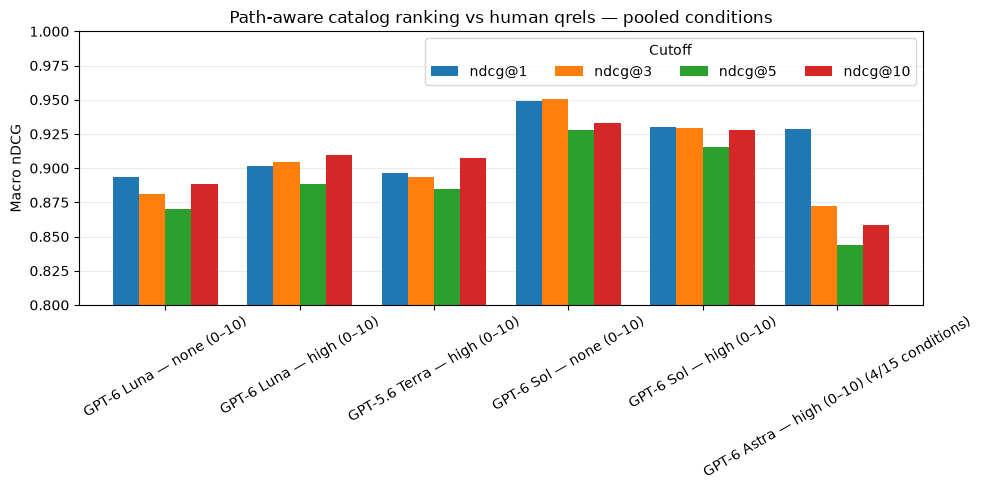

In [21]:
run_order = list(RUN_FILES)
overall = per_condition.groupby('run')[list(METRICS)].mean().reindex(run_order)
display(overall.round(3))
coverage = per_condition.groupby('run')['condition_id'].nunique()
plot_overall = overall.rename(index=lambda name: f'{name} ({coverage.get(name, 0)}/15 conditions)' if coverage.get(name, 0) < 15 else name)
ax = plot_overall.plot(kind='bar', figsize=(10, 5), ylim=(0.8, 1), width=0.78)
ax.set_title('Path-aware catalog ranking vs human qrels — pooled conditions')
ax.set_ylabel('Macro nDCG'); ax.set_xlabel(''); ax.grid(axis='y', alpha=.25); ax.set_axisbelow(True)
ax.legend(title='Cutoff', ncols=4); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## Per-condition nDCG@5

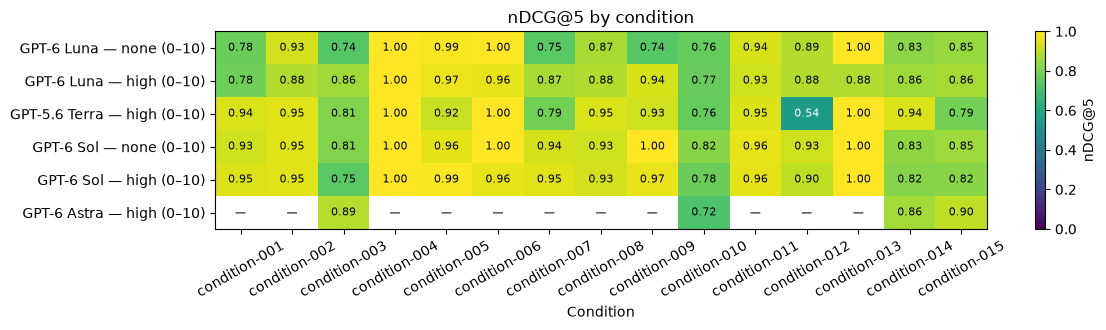

In [24]:
cond_order = per_condition[['suite', 'condition_id']].drop_duplicates().sort_values(['suite', 'condition_id'])
heat = per_condition.pivot(index='run', columns=['suite', 'condition_id'], values='ndcg@5').reindex(run_order)
cols = [(r.suite, r.condition_id) for r in cond_order.itertuples()]
heat = heat.reindex(columns=pd.MultiIndex.from_tuples(cols))
labels = [c for _, c in cols]
fig, ax = plt.subplots(figsize=(max(12, len(labels)*.8), 3.4))
im = ax.imshow(heat.to_numpy(), aspect='auto', cmap='viridis', vmin=0, vmax=1)
ax.set_yticks(range(len(heat)), heat.index); ax.set_xticks(range(len(labels)), labels)
ax.set_title('nDCG@5 by condition'); ax.set_xlabel('Condition')
for y in range(heat.shape[0]):
    for x in range(heat.shape[1]):
        val = heat.iloc[y, x]
        ax.text(x, y, f'{val:.2f}' if pd.notna(val) else '—', ha='center', va='center', fontsize=8,
                color='white' if val < .55 else 'black')
fig.colorbar(im, ax=ax, label='nDCG@5'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## Browse ranked signals

Select a run and condition to inspect the top signals, their path-aware human-readable meaning, and the human grade.

In [23]:
condition_options = [(c, (s, c)) for s in ACTIVE_SUITES for c in sorted(qrels[s])]
def browse(run_label, suite, cid, top_n=10):
    run = run_data.get((run_label, suite, cid))
    if run is None:
        print(f'No result for {cid} in {run_label}.')
        return
    grades = qrels[suite].get(cid, {})
    display(Markdown(f"### {cid}\n\n**Condition:** {run.get('condition', '')}"))
    rows = []
    signals = run.get('signals', [])
    rank_spans = score_tie_spans(signals)
    for signal in signals[:top_n]:
        candidate_id = signal.get('id', '')
        candidate = candidate_from_dict(signal)
        span = rank_spans.get(candidate_id, (signal.get('rank'), signal.get('rank')))
        rows.append({'rank or tied range': rank_span_label(span), 'human grade': grades.get(candidate_id, 'unjudged'),
                     'utility': signal.get('utility_score'), 'signal': candidate.explain_for_human(GRAPH),
                     'path definition': candidate.describe(GRAPH)})
    display(pd.DataFrame(rows))

if widgets is None:
    browse(run_order[0], *condition_options[0][1])
else:
    run_picker = widgets.Dropdown(options=run_order, description='Run:')
    condition_picker = widgets.Dropdown(options=condition_options, description='Condition:', layout=widgets.Layout(width='55%'))
    output = widgets.Output()
    def refresh(change=None):
        with output:
            clear_output(wait=True)
            suite, cid = condition_picker.value
            browse(run_picker.value, suite, cid)
    run_picker.observe(refresh, names='value')
    condition_picker.observe(refresh, names='value')
    display(widgets.VBox([run_picker, condition_picker, output]))
    refresh()